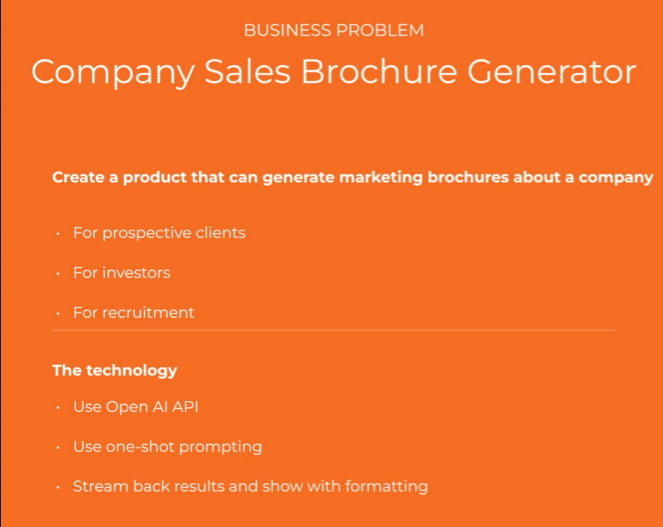

## A Full Business Solution

In [21]:
import os
from dotenv import load_dotenv
from IPython.display import display, Markdown, update_display 
from scraper import fetch_website_contents, fetch_website_links
from openai import OpenAI

In [22]:
load_dotenv(override=True)
api_key = os.getenv("GROQ_API_KEY")

Model = "openai/gpt-oss-20b"
groq = OpenAI(api_key=api_key, base_url="https://api.groq.com/openai/v1")

In [23]:
links = fetch_website_links("https://www.capgemini.com/in-en/")
links

['#main-content',
 'https://www.capgemini.com/in-en',
 'https://www.capgemini.com/in-en',
 'https://www.capgemini.com/in-en/insights/',
 'https://www.capgemini.com/in-en/insights/',
 'https://www.capgemini.com/in-en/insights/',
 'https://www.capgemini.com/in-en/insights/hot-topics/',
 'https://www.capgemini.com/in-en/insights/hot-topics/',
 'https://www.capgemini.com/in-en/insights/hot-topics/reshape-your-future-with-ai/',
 'https://www.capgemini.com/in-en/insights/hot-topics/leading-sustainability/',
 'https://www.capgemini.com/in-en/insights/hot-topics/future-of-technology/',
 'https://www.capgemini.com/in-en/insights/hot-topics/marketing-for-customer-experience/',
 'https://www.capgemini.com/in-en/insights/research-institute/conversations-for-tomorrow/',
 'https://www.capgemini.com/in-en/insights/initiatives-and-research-with-wef/',
 'https://www.capgemini.com/in-en/insights/research-library/',
 'https://www.capgemini.com/in-en/insights/expert-perspectives/',
 'https://www.capgemini

In [24]:
link_system_prompt = """
You are provided with a list of links found on a webpage.
You are able to decide which of the links would be most relevant to include in a brochure about the company,
such as links to an About page, or a Company page, or Careers/Jobs pages.
You should respond in JSON as in this example:

{
    "links": [
        {"type": "about page", "url": "https://full.url/goes/here/about"},
        {"type": "careers page", "url": "https://another.full.url/careers"}
    ]
}
"""

In [25]:
def get_links_user_prompt(url):
    user_prompt = f"""
Here is the list of links on the website {url} -
Please decide which of these are relevant web links for a brochure about the company, 
respond with the full https URL in JSON format.
Do not include Terms of Service, Privacy, email links.

Links (some might be relative links):

"""
    links = fetch_website_links(url)
    user_prompt += "\n".join(links)
    return user_prompt

In [26]:
print(get_links_user_prompt("https://www.capgemini.com/in-en/"))


Here is the list of links on the website https://www.capgemini.com/in-en/ -
Please decide which of these are relevant web links for a brochure about the company, 
respond with the full https URL in JSON format.
Do not include Terms of Service, Privacy, email links.

Links (some might be relative links):

#main-content
https://www.capgemini.com/in-en
https://www.capgemini.com/in-en
https://www.capgemini.com/in-en/insights/
https://www.capgemini.com/in-en/insights/
https://www.capgemini.com/in-en/insights/
https://www.capgemini.com/in-en/insights/hot-topics/
https://www.capgemini.com/in-en/insights/hot-topics/
https://www.capgemini.com/in-en/insights/hot-topics/reshape-your-future-with-ai/
https://www.capgemini.com/in-en/insights/hot-topics/leading-sustainability/
https://www.capgemini.com/in-en/insights/hot-topics/future-of-technology/
https://www.capgemini.com/in-en/insights/hot-topics/marketing-for-customer-experience/
https://www.capgemini.com/in-en/insights/research-institute/conve

In [27]:
import json


def select_relevant_links(url):
    user_prompt = get_links_user_prompt(url)
    response = groq.chat.completions.create(
        model=Model,
        messages=[
            {"role": "system", "content": link_system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        response_format={
            "type": "json_object"
        }
    )
    result = response.choices[0].message.content
    links = json.loads(result)
    return links

In [28]:
print(select_relevant_links("https://www.capgemini.com/in-en/"))

{'links': [{'type': 'home page', 'url': 'https://www.capgemini.com/in-en/'}, {'type': 'about page', 'url': 'https://www.capgemini.com/in-en/about-us/'}, {'type': 'who we are', 'url': 'https://www.capgemini.com/in-en/about-us/who-we-are/'}, {'type': 'what we do', 'url': 'https://www.capgemini.com/in-en/about-us/who-we-are/what-we-do/'}, {'type': 'our way', 'url': 'https://www.capgemini.com/in-en/about-us/who-we-are/the-way-we-work/'}, {'type': 'values', 'url': 'https://www.capgemini.com/in-en/about-us/who-we-are/values-and-ethics/'}, {'type': 'management & governance', 'url': 'https://www.capgemini.com/in-en/about-us/management-and-governance/'}, {'type': 'locations', 'url': 'https://www.capgemini.com/in-en/about-us/locations/'}, {'type': 'our brands', 'url': 'https://www.capgemini.com/in-en/about-us/our-brands/'}, {'type': 'services', 'url': 'https://www.capgemini.com/in-en/services/'}, {'type': 'industries', 'url': 'https://www.capgemini.com/in-en/industries/'}, {'type': 'careers page

## Make Company Brochure

In [29]:
def fetch_page_and_all_relevant_links(url):
    contents = fetch_website_contents(url)
    relevant_links = select_relevant_links(url)
    result = f"## Landing Page:\n\n{contents}\n## Relevant Links:\n"
    for link in relevant_links['links']:
        result += f"\n\n### Link: {link['type']}\n"
        result += fetch_website_contents(link["url"])
    return result

In [30]:
print(fetch_page_and_all_relevant_links("https://huggingface.co/"))

Some characters could not be decoded, and were replaced with REPLACEMENT CHARACTER.


## Landing Page:

Hugging Face – The AI community building the future.

Hugging Face
Models
Datasets
Spaces
Buckets
Docs
Enterprise
Pricing
Website
Tasks
HuggingChat
Collections
Languages
Organizations
Community
Blog
Posts
Daily Papers
Hardware
Learn
Discord
Forum
GitHub
Solutions
Team & Enterprise
Hugging Face PRO
Enterprise Support
Inference Providers
Inference Endpoints
Storage Buckets
Log In
Sign Up
The AI community building the future.
The platform where the machine learning community collaborates on models, datasets, and applications.
Explore AI Apps
or
Browse 2M+ models
Trending on
this week
Models
nvidia/NVIDIA-Nemotron-3.5-Transcribe-30B-A4B
Updated
6 days ago
•
44.9k
•
3.01k
speridlabs/idol
Updated
6 days ago
•
14.6k
•
640
deepseek-ai/DeepSeek-V4.1-Flash-1017
Updated
19 days ago
•
222k
•
5.29k
moonshotai/Kimi-K3.1-Pro
Updated
3 days ago
•
797
•
602
LiquidAI/LFM3-1.7B
Updated
1 day ago
•
55k
•
1.5k
Browse 2M+ models
Spaces
Paused
MCP
271
Qwen Image 2.1 Uncensored
🖼
271
Uncenso

In [31]:
brochure_system_prompt = """
You are an assistant that analyzes the contents of several relevant pages from a company website
and creates a short brochure about the company for prospective customers, investors and recruits.
Respond in markdown without code blocks.
Include details of company culture, customers and careers/jobs if you have the information.
"""

# Or uncomment the lines below for a more humorous brochure - this demonstrates how easy it is to incorporate 'tone':

# brochure_system_prompt = """
# You are an assistant that analyzes the contents of several relevant pages from a company website
# and creates a short, humorous, entertaining, witty brochure about the company for prospective customers, investors and recruits.
# Respond in markdown without code blocks.
# Include details of company culture, customers and careers/jobs if you have the information.
# """

In [32]:

def get_brochure_user_prompt(company_name, url):
    user_prompt = f"""
You are looking at a company called: {company_name}
Here are the contents of its landing page and other relevant pages;
use this information to build a short brochure of the company in markdown without code blocks.\n\n
"""
    user_prompt += fetch_page_and_all_relevant_links(url)
    user_prompt = user_prompt[:5_000] # Truncate if more than 5,000 characters
    return user_prompt 

In [33]:
get_brochure_user_prompt("HuggingFace", "https://huggingface.co") 

'\nYou are looking at a company called: HuggingFace\nHere are the contents of its landing page and other relevant pages;\nuse this information to build a short brochure of the company in markdown without code blocks.\n\n\n## Landing Page:\n\nHugging Face – The AI community building the future.\n\nHugging Face\nModels\nDatasets\nSpaces\nBuckets\nDocs\nEnterprise\nPricing\nWebsite\nTasks\nHuggingChat\nCollections\nLanguages\nOrganizations\nCommunity\nBlog\nPosts\nDaily Papers\nHardware\nLearn\nDiscord\nForum\nGitHub\nSolutions\nTeam & Enterprise\nHugging Face PRO\nEnterprise Support\nInference Providers\nInference Endpoints\nStorage Buckets\nLog In\nSign Up\nThe AI community building the future.\nThe platform where the machine learning community collaborates on models, datasets, and applications.\nExplore AI Apps\nor\nBrowse 2M+ models\nTrending on\nthis week\nModels\nnvidia/NVIDIA-Nemotron-3.5-Transcribe-30B-A4B\nUpdated\n6 days ago\n•\n44.9k\n•\n3.01k\nsperidlabs/idol\nUpdated\n7 days 

In [38]:
def create_brochure(company_name, url):
    response = groq.chat.completions.create(
        model="openai/gpt-oss-20b",
        reasoning_effort="low",
        messages=[
            {"role": "system", "content": brochure_system_prompt},
            {"role": "user", "content": get_brochure_user_prompt(company_name, url)}
        ],
    )
    result = response.choices[0].message.content
    display(Markdown(result))

In [39]:

create_brochure("HuggingFace", "https://huggingface.co")

# Hugging Face – The AI Community Building the Future

## Who We Are
Hugging Face is the world’s premier collaboration hub for machine‑learning creators, researchers, and developers.  
* **Open‑source first** – Every model, dataset, and application lives in the public domain so that anyone can experiment, improve, and build on top of it.  
* **Community‑driven** – With 2 million+ models, 500 k+ datasets, and a vibrant forum, the Hugging Face ecosystem connects thousands of contributors across academia, industry, and hobbyist circles.  
* **Enterprise‑ready** – From inference endpoints and storage buckets to dedicated support, we turn open‑source research into production‑grade solutions.

## What We Offer

| Product | What it does | Who benefits |
|---------|--------------|--------------|
| **Models** | Browse, fine‑tune, and deploy over 2 million pretrained models spanning text, vision, audio, and multimodal tasks. | Researchers, data scientists, product teams |
| **Datasets** | Host and share 500 k+ datasets, from public benchmarks to proprietary collections. | Researchers, educators, developers |
| **Spaces** | One‑click AI apps (chatbots, image generators, video editors) powered by Hugging Face Inference. | Developers, designers, non‑technical users |
| **Buckets** | Scalable object storage for datasets and model artifacts with low‑latency access. | Teams, enterprises |
| **Inference Endpoints** | Deploy models globally with auto‑scaling and GPU acceleration. | Enterprises, SaaS products |
| **Enterprise Support** | Dedicated help, SLAs, and customized onboarding. | Corporate clients |
| **HuggingChat** | Conversational AI powered by the latest multimodal models. | Developers, content creators |

## How We Move Faster

* **HF Open‑Source Stack** – A unified library (`transformers`, `datasets`, `tokenizers`, `accelerate`) that simplifies training, evaluation, and deployment across CPUs, GPUs, and TPUs.  
* **Zero‑MQ and MCP** – Seamless, low‑latency inference for real‑time applications.  
* **Community‑Curated Collections** – Pre‑packaged pipelines for NLP, computer vision, audio, and more.

## Our Culture

| Pillar | What it Means |
|--------|---------------|
| **Inclusivity** | A global community that welcomes contributors of all backgrounds and skill levels. |
| **Transparency** | Open discussions on GitHub, Discord, and the forum; every decision is documented and publicly debated. |
| **Rapid Experimentation** | “Run on Zero” – spin up a model instantly; iterate in minutes, not weeks. |
| **Impact‑Focused** | Projects that solve real‑world problems (e.g., AI for cybersecurity, medical imaging, and creative arts). |

## Who Uses Hugging Face

| Industry | Typical Use‑case |
|----------|------------------|
| **Tech & SaaS** | Chatbots, recommendation engines, AI assistants. |
| **Healthcare** | Medical image analysis, clinical NLP, drug discovery. |
| **Finance** | Risk modeling, fraud detection, market analysis. |
| **Media & Entertainment** | Text generation, video synthesis, 3D object creation. |
| **Education** | Curriculum materials, research projects, student competitions. |

## Careers at Hugging Face

We’re hiring across the entire tech stack – from engineering and product to community and outreach.  
**Current Openings:**  
[View all positions](https://huggingface.co/careers) (software engineering, data science, ML research, platform engineering, product, design, community, sales, etc.)  

**Why Join?**  
* Work on cutting‑edge AI that touches millions of users.  
* A flat, open‑source culture where your contributions go public and get recognized.  
* Flexible work arrangements, competitive benefits, and opportunities for growth.  

---

### Get Started
- **Explore Models** – 2M+ ready‑to‑use models: [huggingface.co/models](https://huggingface.co/models)  
- **Build Apps** – Create your own Space in minutes: [huggingface.co/spaces](https://huggingface.co/spaces)  
- **Contribute** – Join the community on GitHub, Discord, or the forum.  

**Hugging Face – because the future of AI is a community effort.**

## Beautify Version of what we have done in Day 5


In [40]:
def stream_brochure(company_name, url):
    stream = groq.chat.completions.create(
        model="openai/gpt-oss-20b",
        reasoning_effort="low",
        messages=[
            {"role": "system", "content": brochure_system_prompt},
            {"role": "user", "content": get_brochure_user_prompt(company_name, url)}
          ],
        stream=True
    )    
    response = ""
    display_handle = display(Markdown(""), display_id=True)
    for chunk in stream:
        response += chunk.choices[0].delta.content or ''
        update_display(Markdown(response), display_id=display_handle.display_id)

In [41]:
stream_brochure("HuggingFace", "https://huggingface.co")

Some characters could not be decoded, and were replaced with REPLACEMENT CHARACTER.


# Hugging Face – The AI Community Building the Future  

**A hub where people share, learn, and create open‑source machine‑learning artifacts.**  

---

## About Us  
Hugging Face is a collaboration platform that brings together data scientists, ML engineers, researchers, and end users.  
- **Central hub:** The Hugging Face Hub hosts over 2 million public models, 500 k+ datasets, and 1 M+ applications (“Spaces”).  
- **Open‑source DNA:** Our core libraries (Transformers, Diffusers, Tokenizers, etc.) are industry‑standard and freely available on GitHub.  
- **Ethics & responsibility:** We champion transparent, fair, and secure AI, providing tools for model auditing, bias mitigation, and responsible deployment.  

---

## What We Offer  

| Category | What you get | Why it matters |
|----------|--------------|----------------|
| **Models** | Browse, fine‑tune, and deploy pre‑trained models (LLMs, vision, audio, etc.). | Jump‑start projects without training from scratch. |
| **Datasets** | Curated, community‑maintained datasets ready for use. | Save time on data collection & cleaning. |
| **Spaces** | No‑code web apps built on Gradio or Streamlit, shareable via a link. | Demo ideas instantly, get feedback, and iterate fast. |
| **Inference Endpoints & Buckets** | Managed hosting for production‑grade inference; scalable storage. | Focus on product, not infra. |
| **Enterprise Plans** | Hugging Face PRO, dedicated support, private spaces, and compliance features. | Tailored for teams, regulated industries, and large‑scale deployments. |

---

## Community & Culture  

- **Open collaboration:** Anyone can contribute a model, dataset, or space—no gatekeepers.  
- **Learning ecosystem:** Documentation, tutorials, daily papers, and an active Discord & forum.  
- **Global contributors:** Thousands of developers worldwide, from hobbyists to industry leaders.  
- **Inclusive values:** Diversity, equity, and inclusion are core to our hiring and community policies.  

---

## Customers & Partners  

- **Startups & SMBs** use Hugging Face to prototype NLP, computer‑vision, and multimodal solutions.  
- **Enterprise clients** (finance, healthcare, retail) deploy production models with Hugging Face PRO.  
- **Academic researchers** rely on our libraries for cutting‑edge experiments.  
- **Hardware partners** (e.g., NVIDIA) collaborate on optimized inference and training stacks.  

---

## Careers  

Hugging Face is building an AI ecosystem—join us to shape the future.  
- **Open‑source engineers** – deepen the core libraries.  
- **Product & UX designers** – craft intuitive tools for millions of users.  
- **Data scientists & research scientists** – push the limits of LLMs, diffusion, and multimodal models.  
- **Customer success & enterprise support** – help clients succeed with our platforms.  

Explore opportunities at the [Careers page](https://huggingface.co/careers) and become part of a community that thrives on sharing knowledge and building ethical AI.

---

## Get Started  

1. **Explore** the Hub: <https://huggingface.co/models>  
2. **Create** a Space: <https://huggingface.co/spaces>  
3. **Join** the community: Discord, GitHub, Twitter, LinkedIn.  
4. **Build** your own AI app—no code needed.  

Hugging Face – **Your gateway to open, collaborative, and responsible AI.**